**Bahasa Indonesia**

# 03 — Observer viewer, fase dan state campuran

Viewer memiliki akses diagnostik ke state global simulator. Endpoint penerima
chat tidak mendapat akses tersebut. Notebook ini adalah replay terpisah,
bukan live tap server. Tujuannya menjelaskan apa yang dapat dilihat observer
dan mengapa satu trajectory tidak mewakili seluruh ensemble noisy.

---

**English**

# 03 — Observer viewer, phase, and mixed states

The viewer has diagnostic access to the simulator's global state. The chat
receiving endpoint has no such access. This notebook is an independent replay,
not a live server tap. It explains what an observer can inspect and why a single
trajectory does not represent a complete noisy ensemble.


In [1]:
from pathlib import Path
import sys, platform, importlib.metadata as metadata
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'pyproject.toml').exists() and (p/'densechat').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cirq, qsimcirq
from IPython.display import display
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
from scripts.notebook_support import style, save, COLORS, bilingual_table
style()
SEED = 20261106
print('Python:', platform.python_version(), '| seed:', SEED)
print({name: metadata.version(name) for name in ['cirq-core', 'qsimcirq', 'numpy', 'matplotlib']})


Python: 3.12.16 | seed: 20261106
{'cirq-core': '1.7.0', 'qsimcirq': '0.22.1', 'numpy': '2.5.4', 'matplotlib': '3.11.2'}


**Bahasa Indonesia**

## 1. Sepuluh tahap dari viewer aktif

Tahap meliputi reset, H, CNOT/Bell pair, distribusi B, encoding fase/flip,
transfer A, dua gate decoding dan pengukuran. Distribusi ideal mengubah
kepemilikan qubit tanpa mengubah state global dengan sendirinya.

---

**English**

## 1. Ten stages from the active viewer

Stages include reset, H, CNOT/Bell pair, B distribution, phase/flip encoding,
A transfer, two decoding gates, and measurement. Ideal distribution changes
qubit ownership without itself changing the global state.


In [2]:
import viewer
trace = viewer.trace_pair('11', noise=0.0, seed=SEED, shots=32)
stage_table = pd.DataFrame([{'stage': s['title'], 'owner A': s['ownership']['A'], 'owner B': s['ownership']['B'],
                              'state': s['state_vector_notation'], 'P(B=0)': s['B']['p0'],
                              'purity global': s['global_purity']} for s in trace['stages']])
display(bilingual_table(stage_table))
assert trace['first_measurement'] == '11' and trace['histogram']['11'] == 32


,tahap / stage,pemilik A / owner A,pemilik B / owner B,state / keadaan,P(B=0),kemurnian global / global purity
0,RESET / INISIALISASI,Bumi,Bumi,|00⟩,1.0,1.0
1,H(A),Bumi,Bumi,0.707|00⟩ + 0.707|10⟩,1.0,1.0
2,"CNOT(A,B): PASANGAN BELL / BELL PAIR",Bumi,Bumi,0.707|00⟩ + 0.707|11⟩,0.5,1.0
3,DISTRIBUSI B / B DISTRIBUTION,Bumi,Mars,0.707|00⟩ + 0.707|11⟩,0.5,1.0
4,ENCODING FASE / ENCODE PHASE,Bumi,Mars,0.707|00⟩ - 0.707|11⟩,0.5,1.0
5,ENCODING FLIP / ENCODE FLIP,Bumi,Mars,-0.707|01⟩ + 0.707|10⟩,0.5,1.0
6,TRANSFER A / A TRANSFER,Mars,Mars,-0.707|01⟩ + 0.707|10⟩,0.5,1.0
7,"DECODE / DEKODE: CNOT(A,B)",Mars,Mars,-0.707|01⟩ + 0.707|11⟩,0.0,1.0
8,DECODE / DEKODE: H(A),Mars,Mars,-1|11⟩,0.0,1.0
9,"UKUR A,B / MEASURE A,B",Mars,Mars,|11⟩,0.0,1.0


**Bahasa Indonesia**

## 2. Fase tidak terlihat pada histogram populasi saja

Encoding `00` dan `10` memiliki populasi basis yang sama sebelum decoding,
tetapi tanda amplitudo relatif berbeda. Off-diagonal density matrix
memperlihatkan coherence. Diagram populasi saja tidak cukup menjelaskan Z.

---

**English**

## 2. Phase is invisible in population histograms alone

Encodings `00` and `10` have the same basis populations before decoding, but
different relative amplitude signs. Off-diagonal density-matrix elements show
coherence. A population diagram alone cannot fully explain Z.


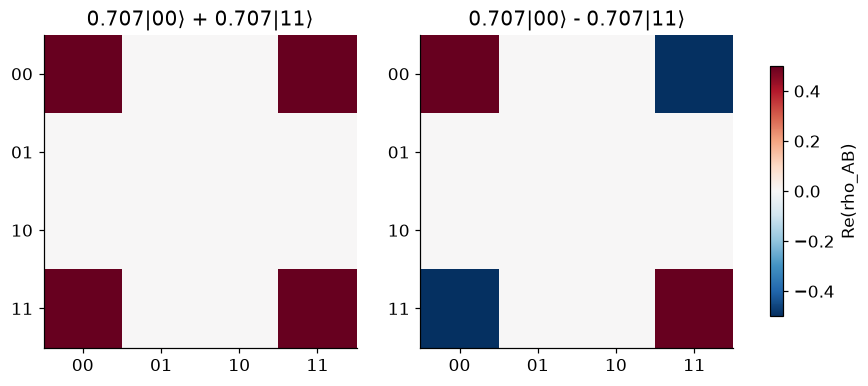

In [3]:
plus = viewer.trace_pair('00', 0.0, SEED, 1)['stages'][5]
minus = viewer.trace_pair('10', 0.0, SEED, 1)['stages'][5]
assert plus['probabilities'] == minus['probabilities']
assert plus['state_vector_notation'] != minus['state_vector_notation']
fig, axes = plt.subplots(1,2,figsize=(8,3.4),constrained_layout=True)
for ax, record in zip(axes,[plus,minus]):
    rho = np.array([[complex(*entry) for entry in row] for row in record['density_matrix']])
    image = ax.imshow(rho.real, vmin=-.5, vmax=.5, cmap='RdBu_r')
    ax.set(title=record['state_vector_notation'],xticks=range(4),yticks=range(4),
           xticklabels=viewer.LABELS,yticklabels=viewer.LABELS)
fig.colorbar(image,ax=axes,label='Re(rho_AB)',shrink=.8)
save(fig,'relative_phase')
display(fig); plt.close(fig)


**Bahasa Indonesia**

## 3. Noise: ensemble eksak dibanding shot yang benar-benar disampling

Untuk depolarisasi A dengan p=0.2, peluang ideal decoding simbol benar
adalah 0.8 dan tiga simbol lain masing-masing 0.2/3. `trace_pair` memakai
Cirq density-matrix untuk ensemble dan qsimcirq untuk shot. Setiap run
mempersiapkan pasangan baru; seed dan jumlah shot dinyatakan eksplisit.

---

**English**

## 3. Noise: exact ensemble versus actually sampled shots

For A depolarization p=0.2, the ideal correct-symbol probability is 0.8 and each
other symbol has probability 0.2/3. `trace_pair` uses Cirq density matrices for
the ensemble and qsimcirq for shots. Each run prepares a fresh pair; seed and
shot count are explicit.


,simbol / symbol,peluang ensemble / ensemble probability,shot aktual / actual shots,fraksi sampel / sample fraction
0,00,0.066667,23,0.044922
1,01,0.066667,41,0.080078
2,10,0.066667,47,0.091797
3,11,0.800000,401,0.783203


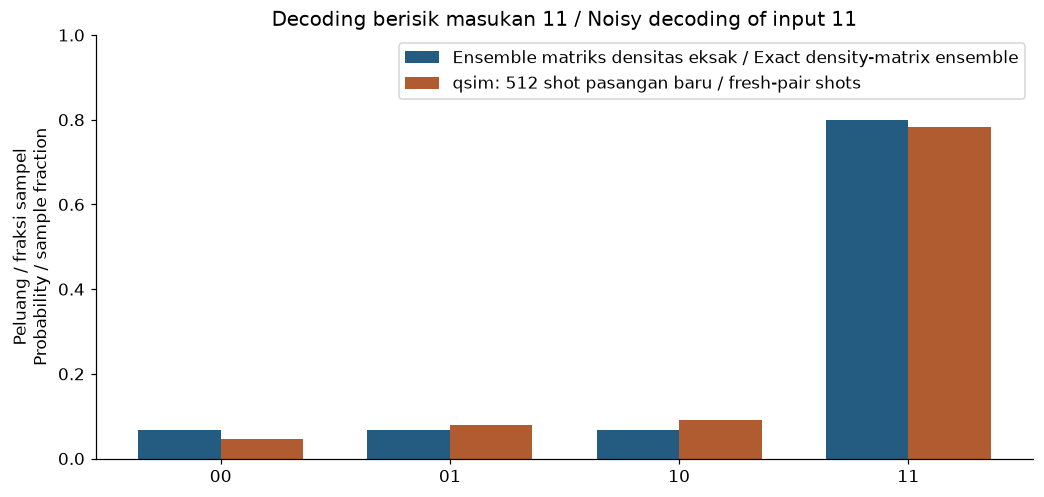

In [4]:
p = 0.2
shots = 512
noisy = viewer.trace_pair('11', p, SEED, shots)
ensemble = noisy['stages'][-2]
assert ensemble['state_vector_notation'] is None
expected = np.array([p/3,p/3,p/3,1-p])
np.testing.assert_allclose(ensemble['probabilities'], expected, atol=1e-12)
observed = np.array([noisy['histogram'][bits] for bits in viewer.LABELS])/shots
display(bilingual_table(pd.DataFrame({'symbol':viewer.LABELS, 'ensemble_probability':expected,
                      'actual_shots':[noisy['histogram'][b] for b in viewer.LABELS], 'sample_fraction':observed})))
x = np.arange(4)
fig, ax = plt.subplots(figsize=(11,5))
ax.bar(x-.18, expected, .36, label='Ensemble matriks densitas eksak / Exact density-matrix ensemble', color=COLORS[0])
ax.bar(x+.18, observed, .36, label=f'qsim: {shots} shot pasangan baru / fresh-pair shots', color=COLORS[1])
ax.set(xticks=x,xticklabels=viewer.LABELS,ylabel='Peluang / fraksi sampel\nProbability / sample fraction',ylim=(0,1),title='Decoding berisik masukan 11 / Noisy decoding of input 11')
ax.legend()
save(fig,'noise_ensemble_vs_shots')
display(fig); plt.close(fig)


**Bahasa Indonesia**

## 4. Purity global dan lokal

Kemurnian $\operatorname{Tr}(\rho^2)$ bernilai satu untuk state murni.
Marginal satu qubit pada Bell state memiliki purity 1/2 meskipun state global
murni. Dalam ensemble noisy, global purity umumnya kurang dari satu. Purity
lokal tidak otomatis merupakan ukuran entanglement untuk state global campuran.

---

**English**

## 4. Global and local purity

Purity $\operatorname{Tr}(\rho^2)$ equals one for a pure state. A one-qubit
marginal of a Bell state has purity 1/2 even though the global state is pure.
In a noisy ensemble, global purity is generally below one. Local purity is not
automatically an entanglement measure for a mixed global state.


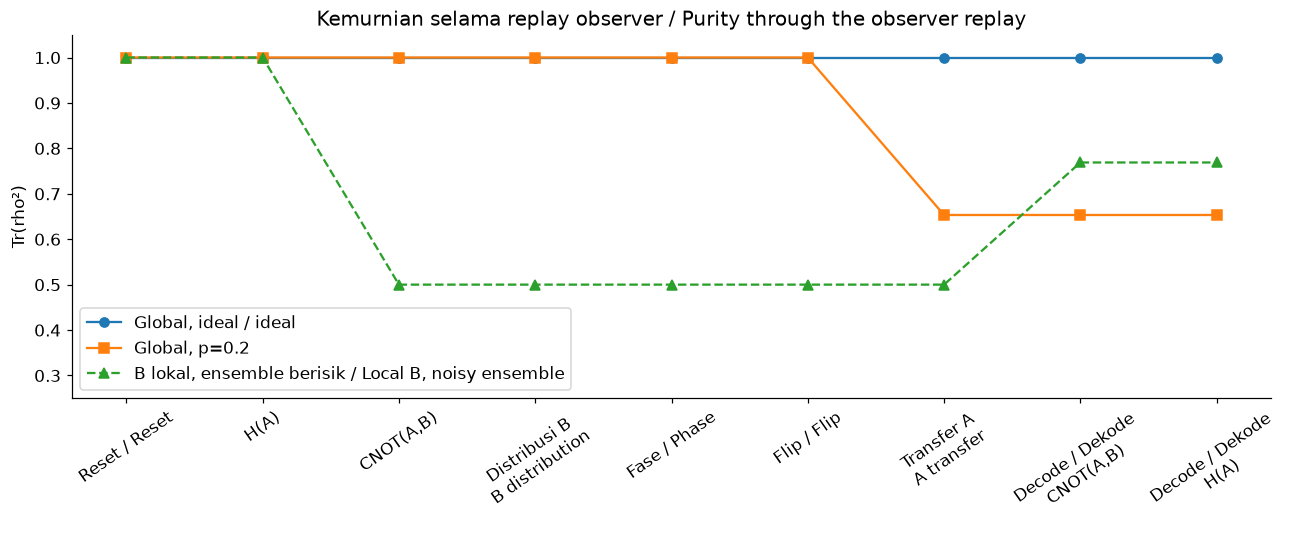

In [5]:
ideal_records = trace['stages'][:-1]
noisy_records = noisy['stages'][:-1]
fig, ax = plt.subplots(figsize=(12,5))
positions = range(len(ideal_records))
ax.plot(positions,[s['global_purity'] for s in ideal_records],'o-',label='Global, ideal / ideal')
ax.plot(positions,[s['global_purity'] for s in noisy_records],'s-',label=f'Global, p={p}')
ax.plot(positions,[s['B']['purity'] for s in noisy_records],'^--',label='B lokal, ensemble berisik / Local B, noisy ensemble')
ax.set(xticks=list(positions),xticklabels=['Reset / Reset', 'H(A)', 'CNOT(A,B)', 'Distribusi B\nB distribution', 'Fase / Phase', 'Flip / Flip', 'Transfer A\nA transfer', 'Decode / Dekode\nCNOT(A,B)', 'Decode / Dekode\nH(A)'],
       ylim=(0.25,1.05),ylabel='Tr(rho²)',title='Kemurnian selama replay observer / Purity through the observer replay')
ax.tick_params(axis='x',labelrotation=35)
ax.legend()
fig.tight_layout()
save(fig,'purity_through_protocol')
display(fig); plt.close(fig)


**Bahasa Indonesia**

## 5. Sesudah pengukuran: state bersyarat satu hasil

Baris akhir viewer menggambarkan state setelah outcome shot pertama
diketahui. Itu bukan ensemble sebelum measurement. Menampilkan satu hasil
sebagai peluang 100% pada tahap tersebut tidak berarti noise hilang atau
seluruh pengulangan menghasilkan simbol yang sama.

---

**English**

## 5. After measurement: the conditional state of one outcome

The viewer's final row shows the state conditional on knowing the first-shot
outcome. It is not the pre-measurement ensemble. Displaying one outcome with
100% probability at this stage does not imply the noise disappeared or that
every repetition yields the same symbol.


In [6]:
first = noisy['first_measurement']
collapsed = noisy['stages'][-1]['probabilities']
assert collapsed[int(first,2)] == 1.0
assert sum(noisy['histogram'].values()) == shots
print('Hasil pertama teramati / First observed outcome:', first)
print('Peluang bersyarat pascapengukuran / Conditional post-measurement probabilities:', dict(zip(viewer.LABELS,collapsed)))
print('Dari persiapan independen / Across independent preparations:', noisy['histogram'])


Hasil pertama teramati / First observed outcome: 11
Peluang bersyarat pascapengukuran / Conditional post-measurement probabilities: {'00': 0.0, '01': 0.0, '10': 0.0, '11': 1.0}
Dari persiapan independen / Across independent preparations: {'00': 23, '01': 41, '10': 47, '11': 401}


**Bahasa Indonesia**

## Memakai viewer terminal

```sh
python viewer.py --bits 11 --step
python viewer.py --message 'Hai!' --pairs 1 --step
python viewer.py --bits 11 --noise 0.2 --shots 512 --json results/trace.json
```

Frame verification dan trace pasangan di mode pesan adalah run terpisah.
State global observer tidak pernah ditransmisikan ke decoder chat. Hasil
notebook ini menjelaskan model simulator, bukan akses quantum state global
yang dapat dilakukan peserta fisik dari lokasi terpisah.

---

**English**

## 6. Using the terminal viewer

```sh
python viewer.py --bits 11 --step
python viewer.py --message 'Hai!' --pairs 1 --step
python viewer.py --bits 11 --noise 0.2 --shots 512 --json results/trace.json
```

Frame verification and pair traces in message mode are separate runs. Observer
global states are never transmitted to the chat decoder. These results describe
the simulator model, not access to a global quantum state physically available
to separated participants.


**Bahasa Indonesia**

## Referensi primer dan cara mengutip

1. C. H. Bennett & S. J. Wiesner (1992), *Communication via one- and two-particle
   operators on Einstein-Podolsky-Rosen states*, Physical Review Letters 69, 2881.
   [DOI: 10.1103/PhysRevLett.69.2881](https://doi.org/10.1103/PhysRevLett.69.2881).
2. [IBM Quantum Learning — superdense coding](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/entanglement-in-action/superdense-coding).
3. [IBM Quantum Learning — reduced states](https://quantum.cloud.ibm.com/learning/en/courses/general-formulation-of-quantum-information/density-matrices/multiple-systems).
4. [Google Quantum AI — qsimcirq](https://quantumai.google/qsim/tutorials/qsimcirq),
   [DepolarizingChannel](https://quantumai.google/reference/python/cirq/DepolarizingChannel).

BibTeX ada pada [docs/references.bib](../docs/references.bib), metadata software
pada [CITATION.cff](../CITATION.cff). Tidak ada DOI software atau klaim peer-review.
Notebook ini merupakan penjelasan dan verifikasi numerik protokol yang sudah ada.

---

**English**

## Primary references and citation

1. C. H. Bennett & S. J. Wiesner (1992), *Communication via one- and two-particle
   operators on Einstein-Podolsky-Rosen states*, Physical Review Letters 69, 2881.
   [DOI: 10.1103/PhysRevLett.69.2881](https://doi.org/10.1103/PhysRevLett.69.2881).
2. [IBM Quantum Learning — superdense coding](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/entanglement-in-action/superdense-coding).
3. [IBM Quantum Learning — reduced states](https://quantum.cloud.ibm.com/learning/en/courses/general-formulation-of-quantum-information/density-matrices/multiple-systems).
4. [Google Quantum AI — qsimcirq](https://quantumai.google/qsim/tutorials/qsimcirq),
   [DepolarizingChannel](https://quantumai.google/reference/python/cirq/DepolarizingChannel).

BibTeX is in [docs/references.bib](../docs/references.bib); software metadata is
in [CITATION.cff](../CITATION.cff). No software DOI or peer-review claim is made.
This notebook explains and numerically verifies an established protocol.
